<a href="https://colab.research.google.com/github/Glaze0/Assignment/blob/main/Multimodal_Data_Myntra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Beyond Tables: Working with Text, Images and Audio

**Myntra, product catalog team.** Every listing is more than a row in a table. A seller uploads a **photo** and types a **title**; a shopper searches by **typing** or by **speaking**.
```
 TEXT  "Puma Men Black Sports Shoes"  ─┐
 IMAGE  👟 60 × 80 photo               ─┼──►  pretrained model  ──►  a list of numbers  ──►  search · classify · combine
 AUDIO  🎤 "show me sneakers for men"  ─┘                           (an embedding)
```

In [ ]:
!gdown 1cn5QSbS7Akt0Mk4erP9TYZnux8qxwLe_

Downloading...
From: https://drive.google.com/uc?id=1cn5QSbS7Akt0Mk4erP9TYZnux8qxwLe_
To: /content/myntra_data.zip
100% 2.51M/2.51M [00:00<00:00, 134MB/s]


In [ ]:
import os, zipfile, textwrap, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from PIL import Image, ImageOps
from scipy.io import wavfile
from sentence_transformers import SentenceTransformer
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from transformers import pipeline
from transformers.utils import logging
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
logging.set_verbosity_error()

if not os.path.exists("myntra_products.csv"):            # Colab: unzip the uploaded data
    zipfile.ZipFile("myntra_data.zip").extractall()

def show(paths, titles=None):                             # a row of product photos
    paths = list(paths); titles = list(titles) if titles is not None else [""] * len(paths)
    fig, axes = plt.subplots(1, len(paths), figsize=(1.9 * len(paths), 2.8), squeeze=False)
    for ax, p, t in zip(axes[0], paths, titles):
        ax.imshow(Image.open(p) if isinstance(p, str) else p); ax.axis("off")
        ax.set_title(textwrap.fill(str(t), 18), fontsize=8)
    plt.tight_layout(); plt.show()

def show_sound(sound, rate):                              # waveform + spectrogram
    fig, (a, b) = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
    a.plot(np.arange(len(sound)) / rate, sound, lw=0.5); a.set_ylabel("air pressure"); a.set_title("Waveform")
    b.specgram(sound, Fs=rate, NFFT=512, noverlap=384, cmap="magma"); b.set_ylabel("frequency (Hz)")
    b.set_xlabel("time (seconds)"); b.set_title("Spectrogram: the same sound as a picture")
    plt.tight_layout(); plt.show()

def move_right(img, px=10):                               # the same photo, shifted px pixels right
    return ImageOps.expand(img, border=(px, 0, 0, 0), fill="white").crop((0, 0) + img.size)

In [ ]:
products = pd.read_csv("myntra_products.csv")
print(products.shape)
products.head()

(1000, 8)


,id,title,article_type,gender,colour,season,usage,image_path
0,54536,F Sports Men Grey Deen Sports Shoes,Sports Shoes,Men,Grey,Fall,Sports,images/54536.jpg
1,51510,Fastrack Men White Dial Watch,Watches,Men,White,Winter,Casual,images/51510.jpg
2,51562,Fastrack Men Black Dial Watch 3062pp02b,Watches,Men,Black,Winter,Casual,images/51562.jpg
3,17673,Catwalk Women Black Pumps,Heels,Women,Black,Winter,Casual,images/17673.jpg
4,17033,Gas Men Europa Casual Shoes,Casual Shoes,Men,Black,Summer,Casual,images/17033.jpg


TABLE: Heels | Women | Orange | Casual
TEXT:  Senorita Women Orange Flats


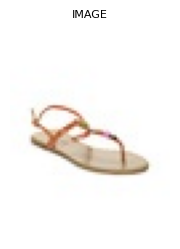

In [ ]:
row = products.iloc[5]
print("TABLE:", row["article_type"], "|", row["gender"], "|", row["colour"], "|", row["usage"])
print("TEXT: ", row["title"])
show([row['image_path']], ['IMAGE'])

In [ ]:
# Multi-Modality : different types of data

In [ ]:
titles = ["Puma Men Black Sports Shoes", "Nike Men White Sports Shoes", "Titan Women Black Watch"]
counter = CountVectorizer() # bag of words
counts = counter.fit_transform(titles)
pd.DataFrame(counts.toarray(), columns=counter.get_feature_names_out(), index=titles)

,black,men,nike,puma,shoes,sports,titan,watch,white,women
Puma Men Black Sports Shoes,1,1,0,1,1,1,0,0,0,0
Nike Men White Sports Shoes,0,1,1,0,1,1,0,0,1,0
Titan Women Black Watch,1,0,0,0,0,0,1,1,0,1


In [ ]:
counter = CountVectorizer().fit(products["title"])       # every word in the catalog
print(len(counter.vocabulary_), "different words in 1,000 titles")
for word in ["shoes", "sneakers", "shades", "purse"]:
    print(f"{word:9s} in the catalog? {word in counter.vocabulary_}")

894 different words in 1,000 titles
shoes     in the catalog? True
sneakers  in the catalog? False
shades    in the catalog? False
purse     in the catalog? False


In [ ]:
all_vectors = counter.transform(products["title"]).toarray()

In [ ]:
all_vectors.shape

(1000, 894)

In [ ]:
all_vectors[0]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [ ]:
# BERT
text_encoder = SentenceTransformer("all-MiniLM-L6-v2")   # a pretrained text model (90 MB)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (3 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
e_sneakers = text_encoder.encode(['sneakers'])
e_sport_shoes = text_encoder.encode(['sport shoes'])
e_wrist_watch = text_encoder.encode(['wrist watch'])

print(e_sneakers.shape)
print(e_wrist_watch.shape)


(1, 384)
(1, 384)


In [ ]:
cosine_similarity(e_sneakers, e_wrist_watch)

array([[0.164372]], dtype=float32)

In [ ]:
cosine_similarity(e_sneakers, e_sport_shoes)

array([[0.77896184]], dtype=float32)

In [ ]:
a = text_encoder.encode(['the food was terrible'])
b = text_encoder.encode(['very bad dishes'])
c = text_encoder.encode(['loved the place.'])

In [ ]:
cosine_similarity(a, b)

array([[0.6135768]], dtype=float32)

In [ ]:
cosine_similarity(a, c)

array([[0.3035469]], dtype=float32)

In [ ]:
# print(a)

In [ ]:
title_vectors = text_encoder.encode(products["title"].tolist())
print(title_vectors.shape)

def search(query, k=5):
    scores = cosine_similarity(text_encoder.encode([query]), title_vectors)[0]
    best = scores.argsort()[::-1][:k]                    # the k most similar titles
    return products.loc[best].assign(score=scores[best].round(2))

(1000, 384)


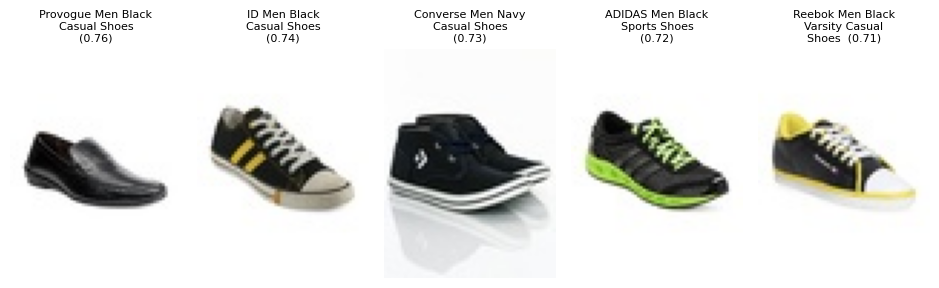

In [ ]:
result = search("sneakers for men")
show(result["image_path"], result["title"] + "  (" + result["score"].astype(str) + ")")

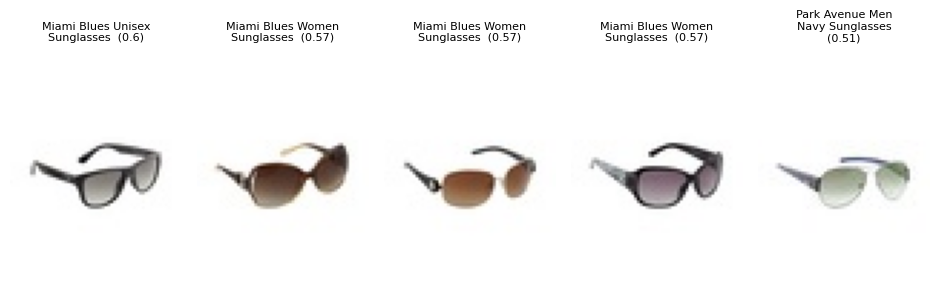

In [ ]:
result = search("shades for beach")
show(result["image_path"], result["title"] + "  (" + result["score"].astype(str) + ")")

# Images

In [ ]:
img = Image.open(products.loc[19, "image_path"])
pixels = np.array(img)
print(pixels.shape)                                       # height, width, 3 colours (R, G, B)
print("corner pixel:", pixels[0, 0], "| centre pixel:", pixels[40, 30])

(80, 60, 3)
corner pixel: [255 255 255] | centre pixel: [151 233 245]


array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[253, 255, 249],
        [254, 255, 251],
        [255, 255, 253],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[251, 255, 250],
        [253, 255, 250],
        [254, 254, 252],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[251, 255, 250],
        [253, 255, 250],
        [254, 254, 252],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]], dtype=uint8)
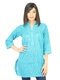

In [ ]:
pixels

In [ ]:
images = [Image.open(p).convert("RGB") for p in products["image_path"]]
def to_pixels(imgs):                                      # each photo -> one long row of numbers
    return np.array([np.array(im) for im in imgs]).reshape(len(imgs), -1) / 255

pixel_features = to_pixels(images)
print(pixel_features.shape)

(1000, 14400)


In [ ]:
pixel_features

array([[1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       ...,
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.]])

In [ ]:
products['article_type'].value_counts()

,count
article_type,
Sports Shoes,100
Watches,100
Heels,100
Casual Shoes,100
Handbags,100
Shirts,100
Tshirts,100
Sunglasses,100
Tops,100


In [ ]:
y = products["article_type"]
train, test = train_test_split(products.index, test_size=0.25, random_state=42, stratify=y)

In [ ]:
pixel_clf = LogisticRegression(max_iter=2000)
pixel_clf.fit(pixel_features[train], y[train])

print("pixels, studio photos:  ", round(pixel_clf.score(pixel_features[test], y[test]), 3))

pixels, studio photos:   0.816


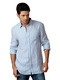

In [ ]:

test_prod = test[1]

img = Image.open(products.loc[test_prod, "image_path"])
img

In [ ]:
test_img = np.array(img).reshape(1, -1)
test_img.shape

(1, 14400)

In [ ]:
pixel_clf.predict(test_img)

array(['Shirts'], dtype=object)

pixels, mirrored photos: 0.504


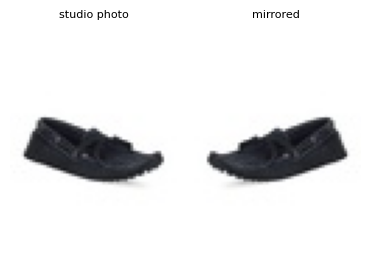

In [ ]:
mirrored = [ImageOps.mirror(images[i]) for i in test]     # a shopper's photo: shoe faces the other way
print("pixels, mirrored photos:", round(pixel_clf.score(to_pixels(mirrored), y[test]), 3))
show([images[test[5]], mirrored[5]], ["studio photo", "mirrored"])

In [ ]:
weights = ResNet18_Weights.DEFAULT
image_encoder = resnet18(weights=weights).eval()          # pretrained on 1.2 million ImageNet photos (45 MB)
prep = transforms.Compose([
    transforms.Resize((160, 120)),                        # bigger, same shape for every photo
    transforms.ToTensor(),                                # 0-255 -> 0-1 (the "divide by 255")
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),   # scale like ImageNet
])

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 103MB/s]


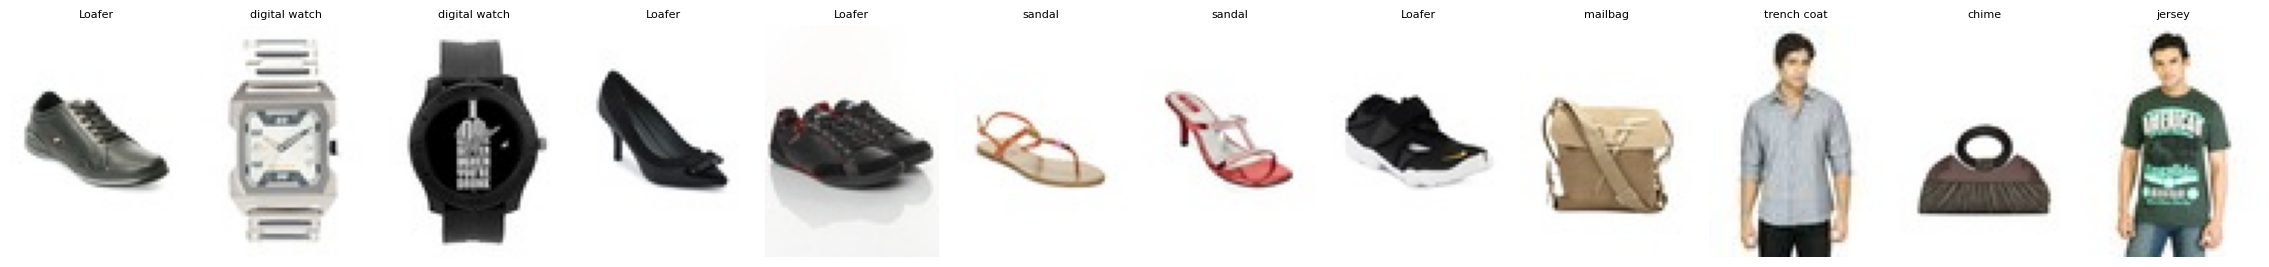

In [ ]:
with torch.no_grad():
    scores = image_encoder(torch.stack([prep(im) for im in images[:12]]))   # 1,000 ImageNet scores each
labels = [weights.meta["categories"][i] for i in scores.argmax(dim=1)]
show(products["image_path"][:12], labels)

In [ ]:
image_encoder.fc = torch.nn.Identity()                    # cut off the last layer: keep the features/embeddings

def embed_images(imgs):
    with torch.no_grad():
        return image_encoder(torch.stack([prep(im) for im in imgs])).numpy()

image_vectors = embed_images(images)                      # ~20-40 seconds on a CPU
print(image_vectors.shape)

(1000, 512)


In [ ]:
image_vectors[0].shape

(512,)

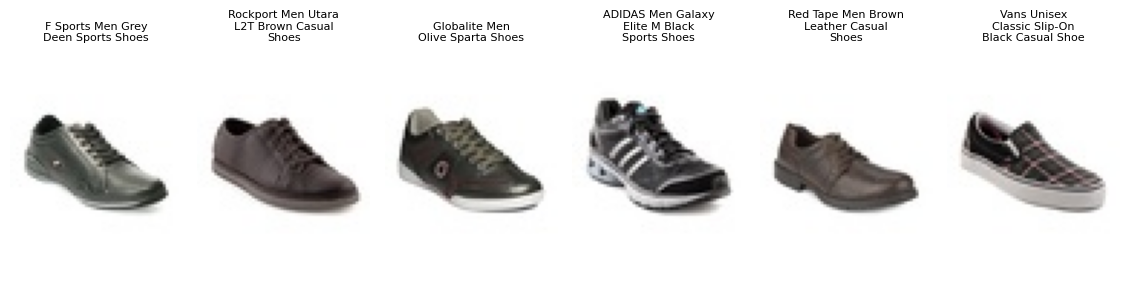

In [ ]:
def more_like_this(i, k=5):
    scores = cosine_similarity(image_vectors[[i]], image_vectors)[0]
    best = scores.argsort()[::-1][:k + 1]                 # first one is the product itself
    show(products.loc[best, "image_path"], products.loc[best, "title"])

more_like_this(0)

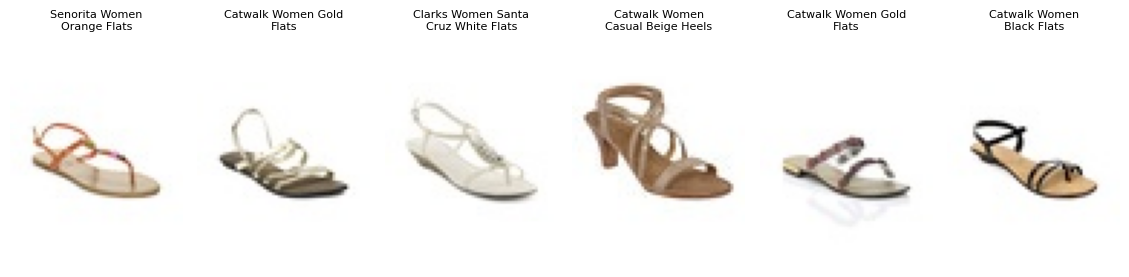

In [ ]:
more_like_this(5)

In [ ]:
image_vectors.shape

(1000, 512)

In [ ]:
y.shape

(1000,)

In [ ]:
# now i m using the embeddings from resnet as features of the images.
image_clf = LogisticRegression(max_iter=2000).fit(image_vectors[train], y[train])
print("ResNet, studio photos:  ", round(image_clf.score(image_vectors[test], y[test]), 3))


ResNet, studio photos:   0.848


In [ ]:
mirror_emb = embed_images(mirrored)

In [ ]:
mirror_emb.shape

(250, 512)

In [ ]:
print("ResNet, mirrored photos:", round(image_clf.score(embed_images(mirrored), y[test]), 3))

ResNet, mirrored photos: 0.836


# Audio

In [ ]:
rate, sound = wavfile.read("voice/voice_1.wav")
print(rate, "samples per second")
print(len(sound), "samples ->", round(len(sound) / rate, 2), "seconds")
print(sound[8000:8010])                                    # just numbers: air pressure over time

16000 samples per second
25264 samples -> 1.58 seconds
[-2145    23 -1239 -1395   764  -779 -2059   -89 -1312 -1853]


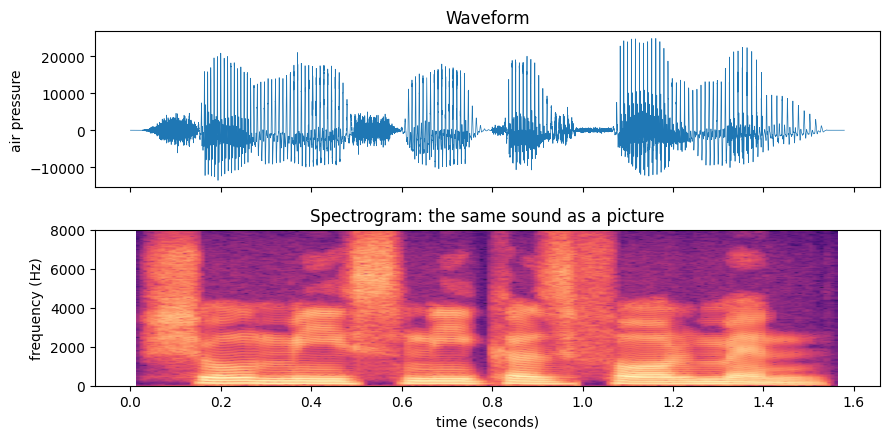

In [ ]:
show_sound(sound, rate)

In [ ]:
speech_to_text = pipeline("automatic-speech-recognition", model="openai/whisper-tiny")   # 150 MB
text = speech_to_text({"raw": sound / 32768, "sampling_rate": rate})["text"]   # 16-bit -> -1..1
print(text)

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  151MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.75k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

... (4 outputs left out)

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

 Show me sneakers for men.


In [ ]:
text = speech_to_text("voice/voice_1.wav")['text']
text

' Show me sneakers for men.'

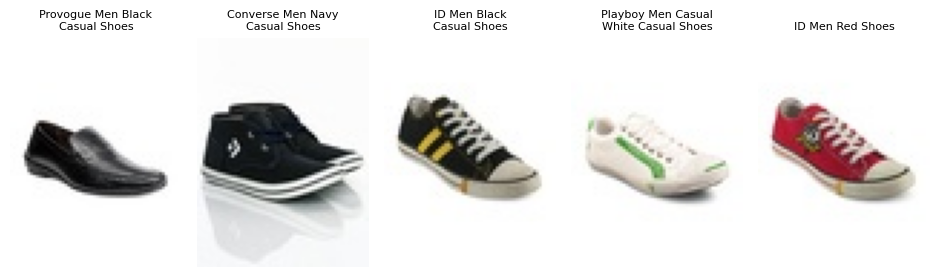

In [ ]:
results = search(text)
show(results['image_path'], results['title'])

# Classification

- "description/title of product" -> category
- "image" -> category


## Combine both
- "title" + "image" -> category

In [ ]:
# Restore the correct test variable from train_test_split
train_indices, test_indices = train_test_split(products.index, test_size=0.25, random_state=42, stratify=y)

In [ ]:
text_clf = LogisticRegression(max_iter=2000).fit(title_vectors[train_indices], y[train_indices])

In [ ]:
print("text only: ", round(text_clf.score(title_vectors[test_indices], y[test_indices]), 3))

text only:  0.964


In [ ]:
title_vectors.shape

(1000, 384)

In [ ]:
img_clf = LogisticRegression(max_iter=2000).fit(image_vectors[train_indices], y[train_indices])
print("image only: ", round(img_clf.score(image_vectors[test_indices], y[test_indices]), 3))

image only:  0.848


In [ ]:
image_vectors.shape

(1000, 512)

In [ ]:
both = np.hstack([image_vectors, title_vectors])
both.shape

(1000, 896)

In [ ]:
both_clf = LogisticRegression(max_iter=2000)
both_clf.fit(both[train_indices], y[train_indices])
print("combined text+image only: ", round(both_clf.score(both[test_indices], y[test_indices]), 3))

combined text+image only:  0.848


In [ ]:
title_vectors.min(axis=0).round(3)

array([-0.176, -0.141, -0.158, -0.093, -0.17 , -0.125, -0.089, -0.148,
       -0.161, -0.125, -0.088, -0.213, -0.136, -0.124, -0.142, -0.115,
       -0.109, -0.163, -0.13 , -0.135, -0.14 , -0.206, -0.122, -0.083,
       -0.214, -0.161, -0.124, -0.1  , -0.133, -0.148, -0.135, -0.089,
       -0.135, -0.085, -0.146, -0.194, -0.1  , -0.131, -0.145, -0.095,
       -0.128, -0.173, -0.146, -0.177, -0.146, -0.152, -0.104, -0.1  ,
       -0.148, -0.099, -0.109, -0.126, -0.13 , -0.132, -0.098, -0.169,
       -0.16 , -0.169, -0.109, -0.173, -0.099, -0.091, -0.16 , -0.097,
       -0.148, -0.11 , -0.143, -0.113, -0.146, -0.125, -0.116, -0.133,
       -0.131, -0.091, -0.117, -0.078, -0.09 , -0.148, -0.147, -0.123,
       -0.17 , -0.175, -0.129, -0.077, -0.102, -0.128, -0.113, -0.115,
       -0.136, -0.149, -0.2  , -0.087, -0.142, -0.138, -0.179, -0.096,
       -0.138, -0.145, -0.153, -0.002, -0.106, -0.13 , -0.105, -0.145,
       -0.157, -0.142, -0.116, -0.167, -0.12 , -0.125, -0.108, -0.106,
      

In [ ]:
title_vectors.max(axis=0).round(3)

array([ 0.068,  0.141,  0.115,  0.147,  0.146,  0.128,  0.225,  0.118,
        0.088,  0.111,  0.145,  0.135,  0.11 ,  0.102,  0.113,  0.146,
        0.165,  0.128,  0.14 ,  0.14 ,  0.112,  0.084,  0.117,  0.134,
        0.043,  0.152,  0.116,  0.125,  0.105,  0.091,  0.094,  0.157,
        0.153,  0.137,  0.12 ,  0.092,  0.14 ,  0.142,  0.122,  0.134,
        0.109,  0.054,  0.099,  0.173,  0.138,  0.138,  0.131,  0.144,
        0.111,  0.183,  0.153,  0.069,  0.111,  0.126,  0.177,  0.132,
        0.094,  0.1  ,  0.148,  0.091,  0.179,  0.154,  0.051,  0.108,
        0.188,  0.152,  0.131,  0.141,  0.138,  0.14 ,  0.165,  0.088,
        0.092,  0.177,  0.15 ,  0.181,  0.15 ,  0.076,  0.122,  0.145,
        0.075,  0.086,  0.166,  0.175,  0.12 ,  0.15 ,  0.11 ,  0.113,
        0.117,  0.115,  0.069,  0.137,  0.102,  0.105,  0.12 ,  0.108,
        0.115,  0.174,  0.122,  0.164,  0.142,  0.138,  0.19 ,  0.103,
        0.101,  0.079,  0.158,  0.182,  0.18 ,  0.141,  0.128,  0.141,
      

In [ ]:
image_vectors.min(axis=0).round(3)

array([0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.053, 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.213, 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.199, 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.004, 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   ,

In [ ]:
image_vectors.max(axis=0).round(3)

array([ 6.15 ,  2.99 ,  6.447,  5.576,  5.504,  5.431,  6.824,  3.229,
        7.588,  7.257,  8.078,  4.253,  6.421,  4.218,  4.162,  9.529,
        2.429,  3.661,  4.68 ,  4.761,  4.691,  3.448,  6.858,  4.128,
        3.46 ,  9.639,  4.139,  8.478,  4.238,  5.501,  3.684,  5.835,
        5.209,  6.944,  6.325,  6.659,  3.786,  4.527,  4.273,  4.07 ,
        4.73 ,  4.169,  5.48 ,  4.818,  6.832,  5.045,  4.782,  1.459,
        4.721,  5.067,  5.379,  6.011,  5.098,  4.425,  6.859,  4.33 ,
        4.15 ,  7.361,  5.093,  9.238,  2.698,  6.946,  5.314,  7.855,
        4.982,  4.404,  3.051,  5.716,  9.298,  4.687,  5.185,  5.38 ,
        5.033,  7.006,  6.616,  5.217,  7.231,  8.372,  3.428,  5.682,
        5.853, 10.596,  6.226,  6.544,  5.148,  8.717,  3.211,  6.727,
        8.359, 10.107,  2.69 ,  4.402,  5.872,  6.676,  5.753,  9.934,
        4.265,  4.677,  2.569,  7.349,  2.913,  4.564,  5.593,  2.309,
        4.434,  9.465,  7.792,  9.33 ,  5.923,  5.958,  7.733,  4.201,
      

In [ ]:
fusion = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(both[train_indices], y[train_indices])
print("fusion, scaled:    ", round(fusion.score(both[test_indices], y[test_indices]), 3))

fusion, scaled:     0.976
